# Question 1

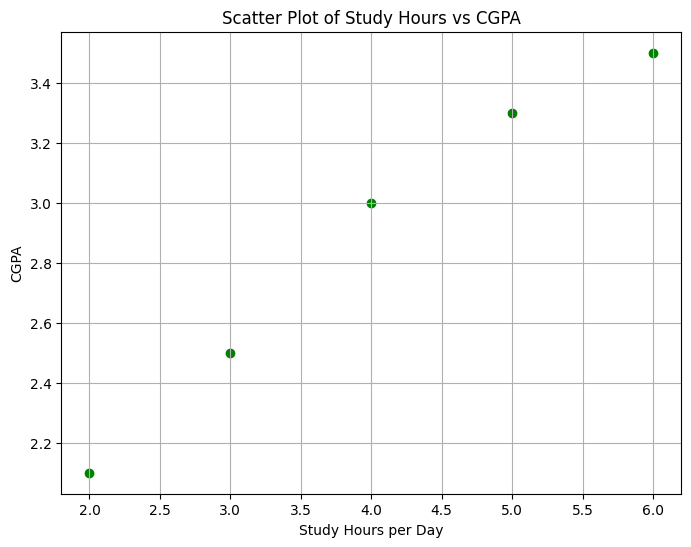

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.976
Model:                            OLS   Adj. R-squared:                  0.968
Method:                 Least Squares   F-statistic:                     121.5
Date:                Thu, 01 May 2025   Prob (F-statistic):            0.00160
Time:                        18:32:04   Log-Likelihood:                 5.5340
No. Observations:                   5   AIC:                            -7.068
Df Residuals:                       3   BIC:                            -7.849
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.4400      0.139     10.392      0.0

c:\Users\Muneeb\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


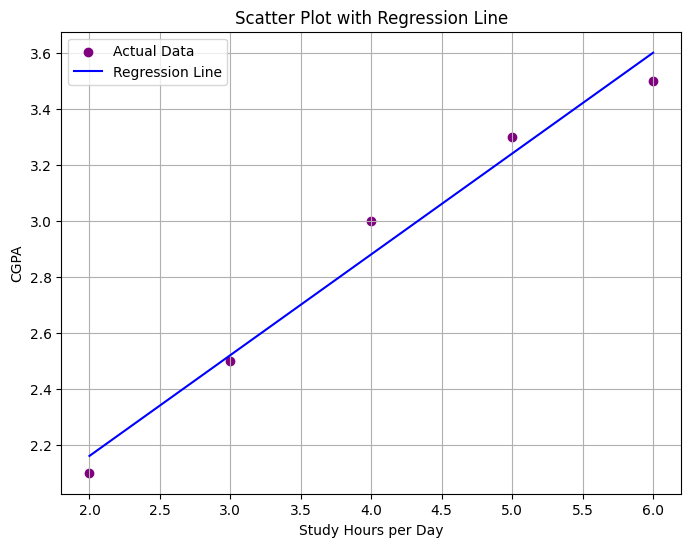

Correlation Coefficient (r): 0.9878783399072131
Confidence Intervals for parameters:
[[0.9990273  1.8809727 ]
 [0.25606174 0.46393826]]
Predicted CGPA for 7 study hours: 3.9599999999999995
SSR (Regression Sum of Squares): 1.2960000000000014
SSE (Error Sum of Squares): 0.03200000000000004
SST (Total Sum of Squares): 1.3279999999999998
Coefficient of Determination (R²): 0.9759036144578312

ANOVA Table:
          sum_sq   df      F    PR(>F)
X          1.296  1.0  121.5  0.001599
Residual   0.032  3.0    NaN       NaN


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

X = np.array([2, 3, 4, 5, 6])
Y = np.array([2.1, 2.5, 3.0, 3.3, 3.5])

plt.figure(figsize=(8, 6))
plt.scatter(X, Y, color='green')
plt.title('Scatter Plot of Study Hours vs CGPA')
plt.xlabel('Study Hours per Day')
plt.ylabel('CGPA')
plt.grid(True)
plt.show()

X_const = sm.add_constant(X)
model = sm.OLS(Y, X_const).fit()
print(model.summary())

plt.figure(figsize=(8, 6))
plt.scatter(X, Y, color='purple', label="Actual Data")
plt.plot(X, model.predict(X_const), color='blue', label="Regression Line")
plt.title('Scatter Plot with Regression Line')
plt.xlabel('Study Hours per Day')
plt.ylabel('CGPA')
plt.legend()
plt.grid(True)
plt.show()

correlation = np.corrcoef(X, Y)[0, 1]
print(f"Correlation Coefficient (r): {correlation}")

conf_intervals = model.conf_int()
print("Confidence Intervals for parameters:")
print(conf_intervals)

new_X = np.array([[1, 7]])
predicted_cgpa = model.predict(new_X)
print(f"Predicted CGPA for 7 study hours: {predicted_cgpa[0]}")

Y_pred = model.predict(X_const)
Y_mean = np.mean(Y)
SST = np.sum((Y - Y_mean)**2)
SSR = np.sum((Y_pred - Y_mean)**2)
SSE = np.sum((Y - Y_pred)**2)

print(f"SSR (Regression Sum of Squares): {SSR}")
print(f"SSE (Error Sum of Squares): {SSE}")
print(f"SST (Total Sum of Squares): {SST}")

R_squared = model.rsquared
print(f"Coefficient of Determination (R²): {R_squared}")

import statsmodels.formula.api as smf
import pandas as pd

data = pd.DataFrame({'X': X, 'Y': Y})
model_formula = smf.ols('Y ~ X', data=data).fit()

from statsmodels.stats.anova import anova_lm
anova_table = anova_lm(model_formula, typ=2)
print("\nANOVA Table:")
print(anova_table)


# Question 2

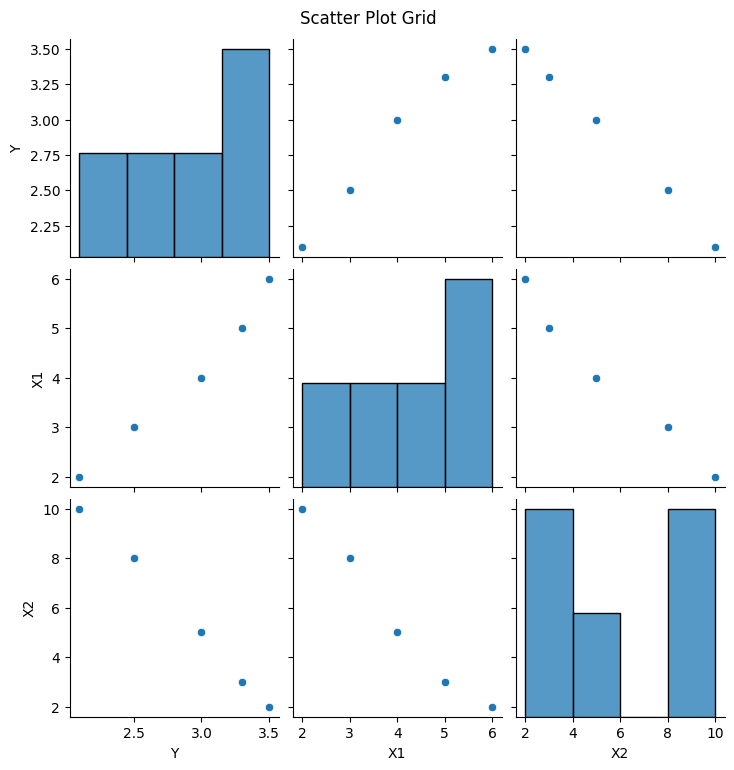

Correlation Matrix:
           Y        X1        X2
Y   1.000000  0.987878 -0.999017
X1  0.987878  1.000000 -0.987757
X2 -0.999017 -0.987757  1.000000
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.996
Method:                 Least Squares   F-statistic:                     520.7
Date:                Thu, 01 May 2025   Prob (F-statistic):            0.00192
Time:                        18:32:41   Log-Likelihood:                 11.863
No. Observations:                   5   AIC:                            -17.73
Df Residuals:                       2   BIC:                            -18.90
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|    

c:\Users\Muneeb\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

data = pd.DataFrame({
    'Y': [2.1, 2.5, 3.0, 3.3, 3.5],
    'X1': [2, 3, 4, 5, 6],
    'X2': [10, 8, 5, 3, 2]
})

sns.pairplot(data)
plt.suptitle("Scatter Plot Grid ", y=1.02)
plt.show()

corr_matrix = data.corr()
print("Correlation Matrix:")
print(corr_matrix)

model = smf.ols('Y ~ X1 + X2', data=data).fit()
print(model.summary())

cov_matrix = model.cov_params()
print("\nVariance-Covariance Matrix:")
print(cov_matrix)

conf_intervals = model.conf_int()
print("\nConfidence Intervals for Parameters:")
print(conf_intervals)

new_data = pd.DataFrame({'X1': [1], 'X2': [4]})
predicted_cgpa = model.predict(new_data)
print(f"\nPredicted CGPA for 1 hr study & 4 hrs internet: {predicted_cgpa.iloc[0]:.4f}")

Y_actual = data['Y']
Y_pred = model.fittedvalues
Y_mean = Y_actual.mean()

SST = sum((Y_actual - Y_mean)**2)
SSR = sum((Y_pred - Y_mean)**2)
SSE = sum((Y_actual - Y_pred)**2)

print(f"\nSST (Total Sum of Squares): {SST:.4f}")
print(f"SSR (Regression Sum of Squares): {SSR:.4f}")
print(f"SSE (Error Sum of Squares): {SSE:.4f}")

R_squared = model.rsquared
print(f"\nR-squared (Coefficient of Determination): {R_squared:.4f}")

anova_results = anova_lm(model, typ=2)
print("\nANOVA Table:")
print(anova_results)
